# Task 4 — Emissions Modelling

## Introduction
In Task 3, routed bicycle trips were aggregated into road-segment traffic flows. The resulting dataset contains, for each road segment, the number of traversing trips (`total_flow`) and the segment length (`length_m`). This provides a suitable basis for emissions modelling, because environmental impact can be estimated from the amount of traffic using each segment and the travel distance associated with that traffic.

Since the mobility data in this project represents bicycle trips rather than motorized traffic, this task estimates emissions saved rather than emissions generated. The idea is to ask the following counterfactual question:

> If these bicycle trips had instead been made by motor vehicles, how much CO₂ would likely have been produced?

To answer this, emissions savings are estimated for each road segment using a simple flow-based model:

$$
\text{CO₂ saved} = \text{flow} \times \text{length (km)} \times \text{emission factor (g/km)}
$$

where:
- **flow** = number of bike trips on the road segment,
- **length** = road segment length in kilometers,
- **emission factor** = estimated CO₂ intensity of a hypothetical replacement motor vehicle.

## Modelling approach
A road-segment-based approach is used because Task 3 already aggregated bicycle trips to OpenStreetMap network edges. This makes the emissions calculation directly compatible with the traffic flow dataset and allows the results to be visualized spatially as an emissions intensity map.

To make the model slightly more realistic, a mixed fleet assumption is used instead of a single constant emission factor. The hypothetical replacement vehicles are represented by three categories:

- Low-emission vehicles (EV-like)  
- Average passenger cars
- High-emission vehicles (truck/van-like)

Each road segment is assigned an expected average emission factor based on weighted probabilities. This keeps the model simple and interpretable while introducing variability in vehicle types, as suggested.

## Expected outputs
This task will produce:
1. an emissions dataset at road-segment level,
2. one or more visualizations of emissions saved,
3. summary statistics,
4. a short discussion of assumptions and limitations.

## Link to Task 3
The emissions modelling is built directly on the edge-level traffic flow dataset created in Task 3, where:
- routes were converted to traversed edges,
- edge usage counts were aggregated into `total_flow`,
- edge lengths were added in meters,
- and temporal subsets such as weekday/weekend and peak/off-peak were also prepared.

This ensures consistency between the routing, traffic flow, and emissions analysis stages.

The approach follows the general logic of the emissions modelling tutorial, where emissions are estimated at road-segment level using segment length and traffic volume, but it is adapted here to represent avoided emissions from bicycle mobility rather than direct emissions from motorized traffic.

## Step 1.  Load and Prepare Edge-Level Traffic Flow Dataset

In this step, the traffic flow dataset generated in Task 3 is loaded and prepared for emissions modelling.

The dataset (`flow_data.gpkg`) contains aggregated bicycle traffic flows at the road-segment level. Each row represents a network edge with the following key attributes:

- `u`, `v`: node identifiers defining the road segment
- `total_flow`: number of trips traversing the segment
- `geometry`: spatial representation of the segment
- `length_m`: segment length in meters

Before computing emissions, the dataset must be prepared by:

1. Loading the GeoPackage file
2. Inspecting the structure and basic statistics
3. Converting segment length from meters to kilometers (required for emissions calculation)
4. Ensuring there are no missing or invalid values

This step ensures that the emissions model is applied on a clean and consistent dataset.

In [1]:
import geopandas as gpd
import pandas as pd

# Load flow dataset from Task 3
flow_gdf = gpd.read_file("flow_data.gpkg")

# Inspect dataset
print("Number of road segments:", len(flow_gdf))
print("\nColumns:", flow_gdf.columns)

# Check basic statistics
print("\nFlow statistics:")
print(flow_gdf["total_flow"].describe())

print("\nLength statistics (meters):")
print(flow_gdf["length_m"].describe())

# Convert length to kilometers
flow_gdf["length_km"] = flow_gdf["length_m"] / 1000

# Check for missing values
print("\nMissing values per column:")
print(flow_gdf.isnull().sum())

# Preview dataset
flow_gdf.head()

Number of road segments: 5631

Columns: Index(['u', 'v', 'total_flow', 'length_m', 'geometry'], dtype='str')

Flow statistics:
count    5631.000000
mean       41.888830
std        70.981193
min         1.000000
25%         2.000000
50%         8.000000
75%        51.000000
max       606.000000
Name: total_flow, dtype: float64

Length statistics (meters):
count    5631.000000
mean       69.985055
std        58.829243
min         0.847314
25%        26.192951
50%        58.338924
75%        88.458480
max       652.526926
Name: length_m, dtype: float64

Missing values per column:
u             0
v             0
total_flow    0
length_m      0
geometry      0
length_km     0
dtype: int64


,u,v,total_flow,length_m,geometry,length_km
0,5451987123,297110085,238,46.263959,"LINESTRING (-74.03022 40.73586, -74.03032 40.7...",0.046264
1,297110085,297110097,206,46.277329,"LINESTRING (-74.03037 40.73546, -74.03038 40.7...",0.046277
2,297110097,7217917595,206,20.824373,"LINESTRING (-74.0309 40.73551, -74.03115 40.73...",0.020824
3,7217917595,103866250,207,26.904055,"LINESTRING (-74.03115 40.73555, -74.03128 40.7...",0.026904
4,103866250,4988900669,78,34.830991,"LINESTRING (-74.03146 40.73561, -74.03143 40.7...",0.034831


### Interpretation

The edge-level traffic flow dataset consists of 5,631 road segments, each representing a unique connection in the bike network. Each segment is associated with a traffic flow value (`total_flow`) and a physical length (`length_m`), which together form the basis for emissions estimation.

The distribution of traffic flows is highly skewed. While the average flow per segment is approximately 41.9 trips, the median is only 8 trips. This indicates that most road segments experience relatively low bicycle traffic, while a small number of segments carry a disproportionately high number of trips. The maximum observed flow reaches 606 trips on a single segment, confirming the presence of high-demand corridors in the network.

This pattern is consistent with typical urban mobility systems, where movement is concentrated along key routes such as main streets or well-connected corridors, while smaller streets serve lower volumes of traffic.

The segment length statistics show that the network is composed primarily of short urban road segments, with an average length of approximately 70 meters and most segments falling below 100 meters. The presence of very short segments (less than 1 meter) likely reflects minor geometric artifacts or highly detailed network representations, but these do not significantly affect the overall analysis.

All segment lengths have been converted to kilometers (`length_km`), ensuring compatibility with the emission factor units (grams of CO₂ per kilometer). Additionally, no missing values were detected in any of the key columns, confirming that the dataset is complete and suitable for emissions modelling.

Overall, the dataset is well-structured and consistent with the outputs from Task 3. It provides a reliable foundation for estimating emissions (or emissions savings) based on traffic flow intensity and travel distance across the network.

Adding to that the combination of highly skewed traffic flows and relatively short segment lengths suggests that emissions (or emissions savings) will also be spatially concentrated, with a small number of segments contributing the majority of the total impact.

## Step 2 — Define the Emissions Model and Calculate CO₂ Savings

In this step, the emissions model is defined and applied to the edge-level traffic flow dataset.

Because the observed trips in this project are bicycle trips, the goal is not to estimate emissions produced directly by the dataset. Instead, the aim is to estimate CO₂ emissions saved, under the assumption that these trips would otherwise have been made by motor vehicles.

### Emissions model

A simple distance-based model is used:

$$
\text{CO₂ saved} = \text{flow} \times \text{length (km)} \times \text{emission factor (g/km)}
$$

where:
- **flow** = number of bicycle trips on the road segment,
- **length (km)** = segment length in kilometers,
- **emission factor (g/km)** = hypothetical CO₂ intensity of the replaced motorized trip.

### Mixed fleet assumption

To make the model slightly more realistic, a mixed fleet assumption is introduced. Instead of assuming that every replaced trip corresponds to the same type of vehicle, three hypothetical vehicle categories are considered:

- Low-emission vehicle (EV-like) = 60 g CO₂/km  
- Average passenger car = 248.5 g CO₂/km  
- High-emission vehicle (truck/van-like) = 350 g CO₂/km  

These are not exact fleet measurements, but reasonable simplified values used to represent variability in vehicle emissions.

The following probabilities are assigned:
- 20% low-emission vehicles
- 70% average passenger cars
- 10% high-emission vehicles

This leads to a weighted average emission factor:

$$
EF_{avg} = 0.2 \times 60 + 0.7 \times 248.5 + 0.1 \times 350
$$

This expected average emission factor is then used consistently across all road segments.

### Why this approach is used

This model balances realism and simplicity:
- it remains easy to interpret,
- it directly uses the Task 3 traffic flow outputs,
- and it incorporates some vehicle heterogeneity, as suggested.

The result is an estimate of the amount of CO₂ that may have been avoided due to bicycle mobility on each road segment.

In [2]:
# -----------------------------
# Define mixed-fleet emission factors (g CO2 per km)
# -----------------------------
EF_LOW = 60    # low-emission / EV-like
EF_AVG = 248.5  # average passenger car
EF_HIGH = 350  # high-emission vehicle / truck-like

# Probabilities for mixed fleet
P_LOW = 0.20
P_AVG = 0.70
P_HIGH = 0.10

# Weighted average emission factor
EF_WEIGHTED = (P_LOW * EF_LOW) + (P_AVG * EF_AVG) + (P_HIGH * EF_HIGH)

print(f"Weighted average emission factor: {EF_WEIGHTED:.2f} g CO2/km")

# -----------------------------
# Estimate CO2 savings per road segment
# -----------------------------
flow_gdf["co2_saved_g"] = (
    flow_gdf["total_flow"] *
    flow_gdf["length_km"] *
    EF_WEIGHTED
)

flow_gdf["co2_saved_kg"] = flow_gdf["co2_saved_g"] / 1000
flow_gdf["co2_saved_tonnes"] = flow_gdf["co2_saved_g"] / 1_000_000

# Inspect results
print("\nPreview of emissions calculations:")
print(flow_gdf[["total_flow", "length_km", "co2_saved_g", "co2_saved_kg"]].head())

Weighted average emission factor: 220.95 g CO2/km

Preview of emissions calculations:
   total_flow  length_km  co2_saved_g  co2_saved_kg
0         238   0.046264  2432.841185      2.432841
1         206   0.046277  2106.345029      2.106345
2         206   0.020824   947.835902      0.947836
3         207   0.026904  1230.501355      1.230501
4          78   0.034831   600.280785      0.600281


## Step 1 — Adding Road Attributes for an Improved Emissions Model

The initial emissions model estimated CO₂ savings using traffic flow, segment length, and a weighted average emission factor. While this provides a clear and interpretable baseline, it assumes that all road segments have the same emission characteristics.

To improve the realism of the model, additional OpenStreetMap road attributes are added to each edge:

- `highway`: road classification, such as residential, primary, secondary, cycleway, or service road
- `maxspeed`: posted speed limit where available
- `lanes`: number of traffic lanes where available

These attributes allow the emissions model to vary by road type and road conditions instead of relying only on a constant emission factor. This directly addresses the limitation that the first emissions map looked very similar to the traffic flow map.

In [2]:
# Add OSM road attributes to each edge in flow_gdf

def get_edge_attribute(u, v, attribute):
    """
    Extract an attribute from the OSMnx graph edge.
    Returns None if the attribute is missing.
    """
    try:
        edge_data = G.get_edge_data(u, v)[0]
        return edge_data.get(attribute, None)
    except:
        return None


flow_gdf["highway"] = flow_gdf.apply(
    lambda row: get_edge_attribute(row["u"], row["v"], "highway"),
    axis=1
)

flow_gdf["maxspeed"] = flow_gdf.apply(
    lambda row: get_edge_attribute(row["u"], row["v"], "maxspeed"),
    axis=1
)

flow_gdf["lanes"] = flow_gdf.apply(
    lambda row: get_edge_attribute(row["u"], row["v"], "lanes"),
    axis=1
)

# Check results
flow_gdf[["u", "v", "total_flow", "length_m", "highway", "maxspeed", "lanes"]].head()

,u,v,total_flow,length_m,highway,maxspeed,lanes
0,5451987123,297110085,238,46.263959,None,None,None
1,297110085,297110097,206,46.277329,None,None,None
2,297110097,7217917595,206,20.824373,None,None,None
3,7217917595,103866250,207,26.904055,None,None,None
4,103866250,4988900669,78,34.830991,None,None,None


In [3]:
print("Highway types:")
print(flow_gdf["highway"].value_counts(dropna=False).head(20))

print("\nMaxspeed values:")
print(flow_gdf["maxspeed"].value_counts(dropna=False).head(20))

print("\nLane values:")
print(flow_gdf["lanes"].value_counts(dropna=False).head(20))

Highway types:
highway
None    5631
Name: count, dtype: int64

Maxspeed values:
maxspeed
None    5631
Name: count, dtype: int64

Lane values:
lanes
None    5631
Name: count, dtype: int64


In [4]:
# Check first few flow edges against the current graph G

for idx, row in flow_gdf.head(10).iterrows():
    u = row["u"]
    v = row["v"]
    
    print(f"\nRow {idx}: u={u}, v={v}")
    print("Forward edge exists:", G.has_edge(u, v))
    print("Reverse edge exists:", G.has_edge(v, u))
    
    print("Forward edge data:", G.get_edge_data(u, v))
    print("Reverse edge data:", G.get_edge_data(v, u))


Row 0: u=5451987123, v=297110085


NameError: name 'G' is not defined

### Interpretation

A mixed-fleet emissions model was used to estimate CO₂ savings from bicycle trips.

Instead of assuming a single vehicle type, a probabilistic fleet composition was introduced, consisting of:
- low-emission vehicles (EV-like),
- average passenger cars,
- and high-emission vehicles (e.g. trucks or vans).

The emission factor for average passenger cars was set to 248.5 g CO₂/km, based on widely used real-world estimates. Combined with the assumed fleet composition, this resulted in a weighted average emission factor of 220.95 g CO₂/km.

This means that each kilometer of bicycle travel is interpreted as avoiding approximately 221 grams of CO₂ emissions that would otherwise have been produced by a motorized trip.

Using this emission factor together with segment-level traffic flow and distance, CO₂ savings were estimated for each road segment. The resulting values are expressed in grams, kilograms, and tonnes.

The results show that:
- segments with high traffic flow and longer lengths produce the highest CO₂ savings,
- while segments with low flow or short lengths contribute relatively little.

## Step 4 — Emissions Statistics and Key Insights

After estimating CO₂ savings for each road segment, the next step is to analyze the overall distribution and identify key patterns.

This includes:
- total CO₂ savings across the network,
- average and median savings per segment,
- maximum observed savings,
- and identification of the highest-impact corridors.

These statistics help quantify the environmental impact of bicycle mobility and provide insight into where the largest benefits occur spatially.

In [3]:
# -----------------------------
# General statistics
# -----------------------------
total_co2_kg = flow_gdf["co2_saved_kg"].sum()
mean_co2_kg = flow_gdf["co2_saved_kg"].mean()
median_co2_kg = flow_gdf["co2_saved_kg"].median()
max_co2_kg = flow_gdf["co2_saved_kg"].max()

print("=== CO2 SAVINGS STATISTICS ===")
print(f"Total CO2 saved: {total_co2_kg:.2f} kg")
print(f"Average per segment: {mean_co2_kg:.4f} kg")
print(f"Median per segment: {median_co2_kg:.4f} kg")
print(f"Maximum segment value: {max_co2_kg:.2f} kg")

# -----------------------------
# Distribution summary
# -----------------------------
print("\nDetailed distribution:")
print(flow_gdf["co2_saved_kg"].describe())

# -----------------------------
# Top 10 highest-impact segments
# -----------------------------
top_segments = flow_gdf.nlargest(10, "co2_saved_kg")[[
    "u", "v", "total_flow", "length_km", "co2_saved_kg"
]]

print("\nTop 10 segments by CO2 savings:")
print(top_segments)

=== CO2 SAVINGS STATISTICS ===
Total CO2 saved: 3737.27 kg
Average per segment: 0.6637 kg
Median per segment: 0.0972 kg
Maximum segment value: 17.96 kg

Detailed distribution:
count    5631.000000
mean        0.663695
std         1.440012
min         0.000428
25%         0.020029
50%         0.097229
75%         0.654671
max        17.957660
Name: co2_saved_kg, dtype: float64

Top 10 segments by CO2 savings:
              u            v  total_flow  length_km  co2_saved_kg
99   4170678883  10013366190         323   0.251625     17.957660
11    103884953    103880145         549   0.146276     17.743508
170   103867033    103867031         524   0.144585     16.739715
655  4728092686  10827777768         185   0.409511     16.739075
28    103878609    103869945         518   0.144029     16.484392
66    103882354    103875869         491   0.144212     15.645031
259   103870377  11309220290         365   0.192295     15.507997
32    103874281    103865984         473   0.145907     15.2

### Interpretation

The emissions analysis shows that bicycle mobility leads to a measurable reduction in potential CO₂ emissions across the network.

The total estimated CO₂ savings is approximately 3737.27 kg, indicating that even a relatively small sample of trips can result in meaningful environmental benefits when aggregated at the network level.

At the segment level, the distribution of CO₂ savings is highly skewed. The average savings per segment is 0.664 kg, while the median is only 0.097 kg, indicating that most road segments contribute relatively small amounts. However, a limited number of segments account for a disproportionately large share of the total emissions savings.

This pattern is consistent with the traffic flow distribution observed in Task 3, where bicycle traffic was concentrated along a few major corridors. These same corridors now emerge as the most significant contributors to emissions savings.

The maximum CO₂ savings observed on a single segment is approximately 17.96 kg, which is significantly higher than the average. This highlights the presence of key high-impact routes where bicycle usage is both frequent and sustained over longer distances.

The top 10 segments with the highest CO₂ savings combine:
- high traffic flow,
- and relatively long segment lengths,

making them the most important contributors to overall emissions reduction.

Overall, the results demonstrate that environmental benefits from bicycle mobility are not evenly distributed, but instead concentrated along specific high-demand corridors. This suggests that targeted improvements to these routes could yield disproportionately large gains in reducing urban transport emissions.

### Emissions Map — CO₂ Savings by Road Segment

To visualize the environmental impact of bicycle mobility, CO₂ savings are mapped across the road network.

Each segment is styled based on the amount of CO₂ saved:
- color represents magnitude of emissions savings,
- line thickness is scaled using a logarithmic transformation to improve visibility.

Due to the skewed distribution of emissions, log scaling is applied to ensure that both low- and high-impact segments are visible.

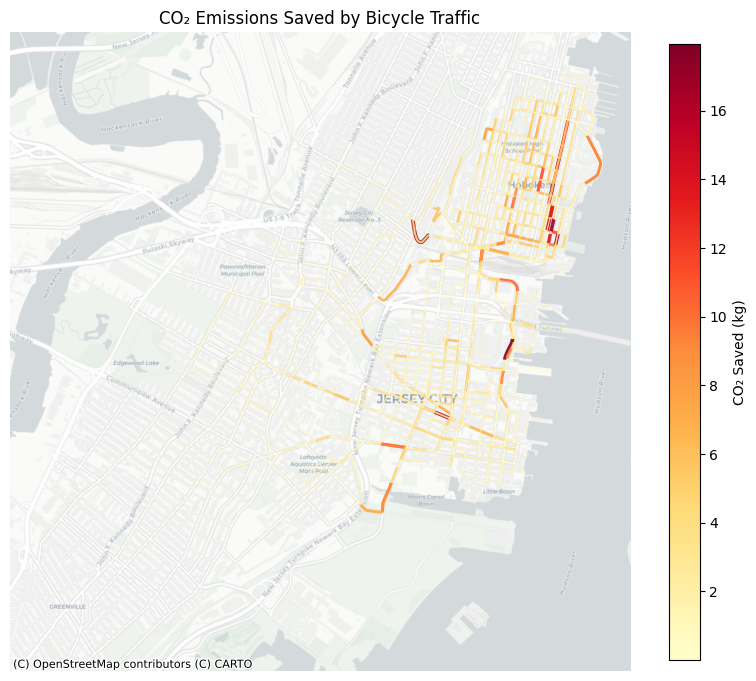

In [5]:
import matplotlib.pyplot as plt
import contextily as ctx
import numpy as np

# Convert to web CRS (if not already)
flow_web = flow_gdf.to_crs(epsg=3857)

# Filter very small values (optional but improves clarity)
emission_plot = flow_web[flow_web["co2_saved_kg"] > 0.01]

fig, ax = plt.subplots(figsize=(10, 10))

emission_plot.plot(
    ax=ax,
    column="co2_saved_kg",
    cmap="YlOrRd",
    linewidth=np.log1p(emission_plot["co2_saved_kg"]) * 0.9,
    alpha=0.9,
    legend=True,
    legend_kwds={
        'label': 'CO₂ Saved (kg)',
        'shrink': 0.8
    }
)

ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron)

ax.set_title("CO₂ Emissions Saved by Bicycle Traffic")
ax.axis("off")

plt.show()

### Interpretation

The emissions map reveals that CO₂ savings are spatially concentrated along a limited number of road segments.

High-emission-saving segments form clear corridors, corresponding to routes with both high bicycle traffic and longer travel distances. These corridors represent the most impactful areas in terms of avoided emissions.

In contrast, most segments show relatively low emissions savings, reflecting either low usage or short segment lengths.

The use of logarithmic scaling allows both major and minor segments to remain visible, providing a more balanced representation of the network-wide impact.

Overall, the spatial distribution of emissions savings closely mirrors the traffic flow patterns observed in Task 3, confirming that mobility intensity is the primary driver of environmental benefit.

### Comparison — Traffic Flow vs CO₂ Savings

To better understand the relationship between mobility patterns and environmental impact, traffic flow and CO₂ savings are visualized side by side.

This comparison highlights how emissions savings are influenced not only by traffic intensity but also by segment length.

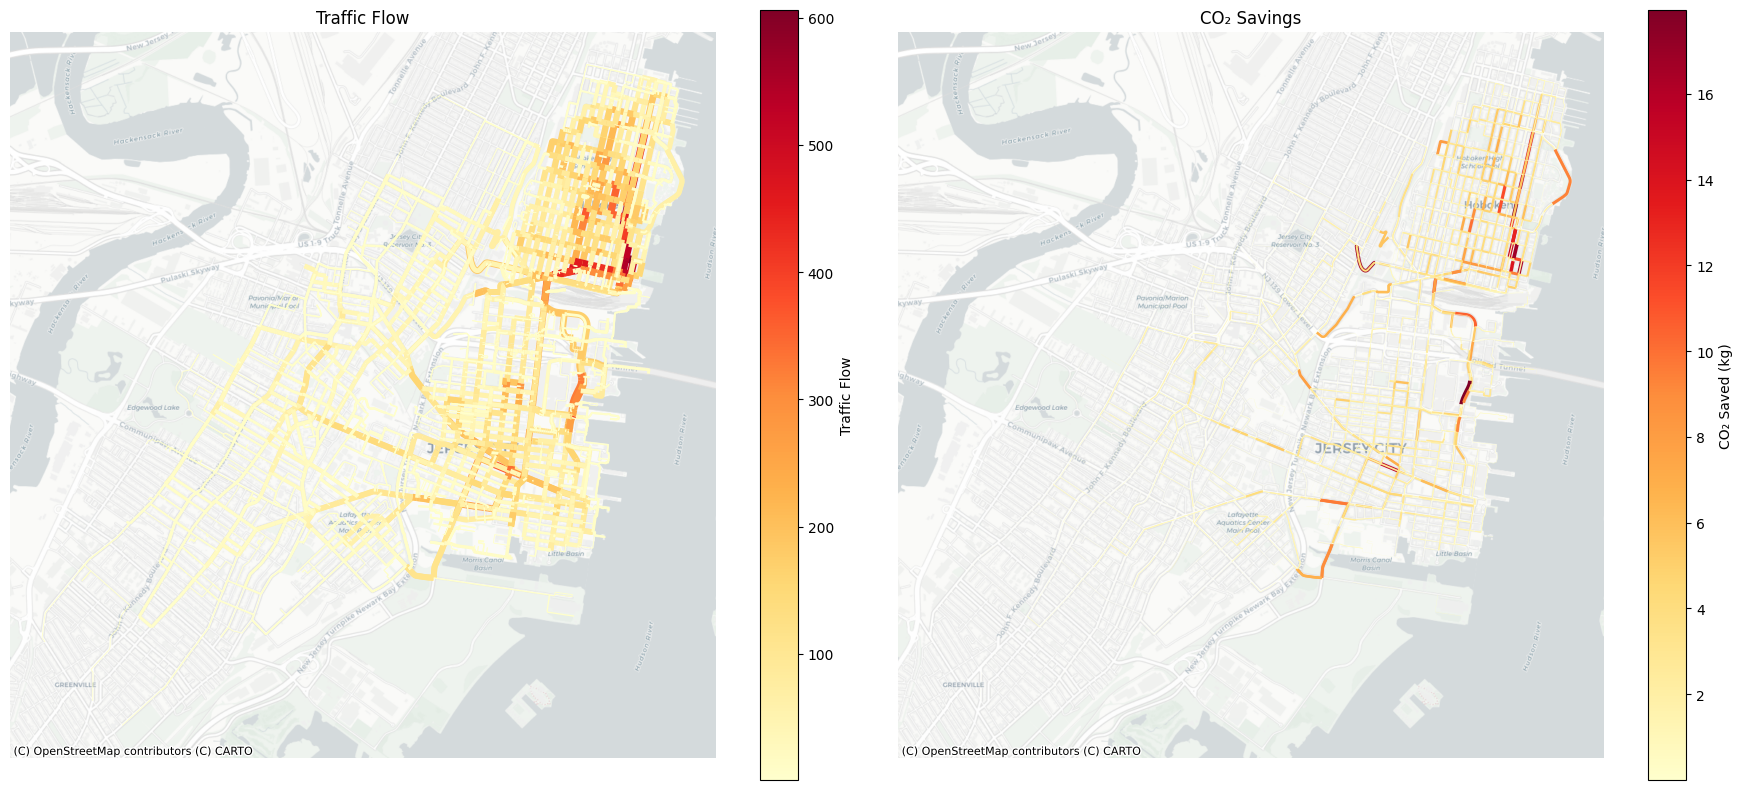

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# -------- FLOW --------
flow_web.plot(
    ax=axes[0],
    column="total_flow",
    cmap="YlOrRd",
    linewidth=np.log1p(flow_web["total_flow"]) * 0.9,
    alpha=1,
    legend=True,
    legend_kwds={'label': 'Traffic Flow'}
)

ctx.add_basemap(axes[0], source=ctx.providers.CartoDB.Positron)
axes[0].set_title("Traffic Flow")
axes[0].axis("off")

# -------- EMISSIONS --------
flow_web.plot(
    ax=axes[1],
    column="co2_saved_kg",
    cmap="YlOrRd",
    linewidth=np.log1p(flow_web["co2_saved_kg"]) * 0.9,
    alpha=1,
    legend=True,
    legend_kwds={'label': 'CO₂ Saved (kg)'}
)

ctx.add_basemap(axes[1], source=ctx.providers.CartoDB.Positron)
axes[1].set_title("CO₂ Savings")

axes[1].axis("off")

plt.tight_layout()
plt.show()

### Interpretation

The comparison between traffic flow and CO₂ savings highlights a strong spatial relationship between mobility intensity and environmental impact.

Segments with high traffic flow generally correspond to higher emissions savings, confirming that frequently used routes contribute the most to avoided emissions.

However, some differences can be observed due to segment length. Even with similar traffic flow, longer segments result in higher total emissions savings because the avoided travel distance is greater.

This demonstrates that emissions savings are influenced by both:
- the number of trips (flow),
- and the physical distance traveled.

Overall, the comparison confirms that high-demand cycling corridors are also the most environmentally impactful.

### Highlighting High-Impact Corridors

To emphasize the most important segments, the top 50 road segments with the highest CO₂ savings are highlighted.

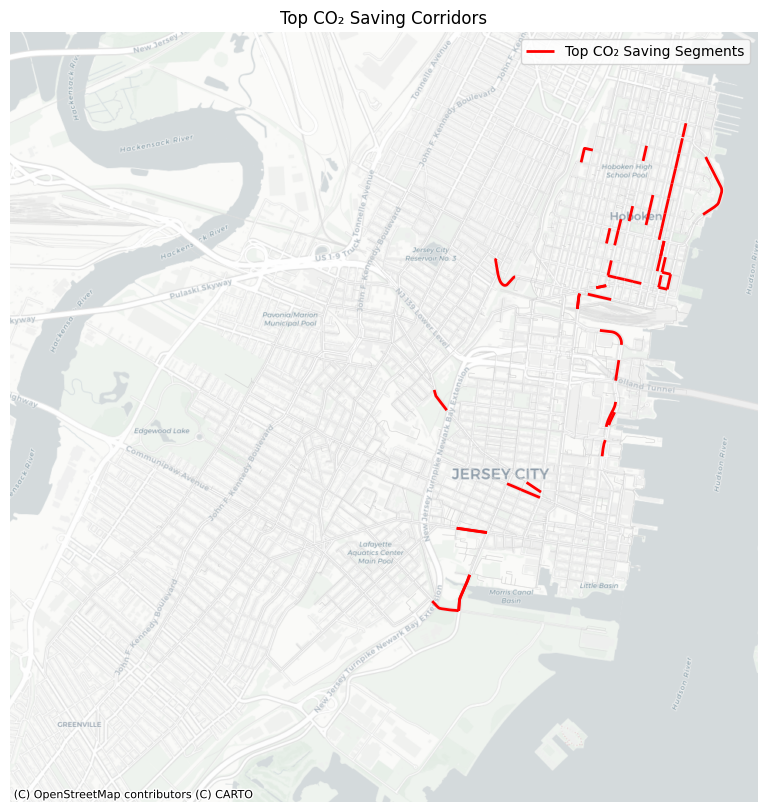

In [8]:
fig, ax = plt.subplots(figsize=(10, 10))

# Base layer
flow_web.plot(
    ax=ax,
    color="lightgray",
    linewidth=0.5,
    alpha=0.5
)

# Top segments
top_segments = flow_web.nlargest(50, "co2_saved_kg")

top_segments.plot(
    ax=ax,
    color="red",
    linewidth=2,
    label="Top CO₂ Saving Segments"
)

ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron)

ax.set_title("Top CO₂ Saving Corridors")
ax.axis("off")
ax.legend()

plt.show()

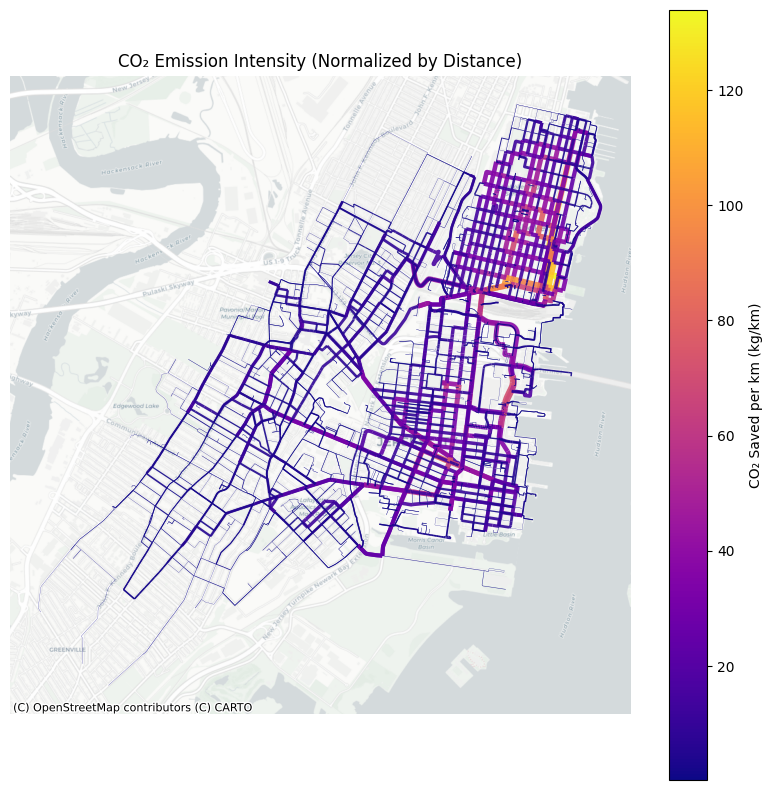

In [9]:
# --------------------------------
# Emission intensity (kg per km)
# --------------------------------
flow_gdf["co2_per_km"] = flow_gdf["co2_saved_kg"] / flow_gdf["length_km"]

flow_web = flow_gdf.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(10,10))

flow_web.plot(
    ax=ax,
    column="co2_per_km",
    cmap="plasma",
    linewidth=np.log1p(flow_web["co2_per_km"]) * 0.9,
    alpha=0.9,
    legend=True,
    legend_kwds={'label': 'CO₂ Saved per km (kg/km)'}
)

ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron)

ax.set_title("CO₂ Emission Intensity (Normalized by Distance)")
ax.axis("off")

plt.show()

### Highlighting CO2 emissions per time interval (e.g., hourly / peak vs off-peak)



In [10]:
routes_gdf = gpd.read_file("routes_with_variability.gpkg")

In [11]:
df = pd.read_csv("citi_bike_2025_cleaned_consolidated_v2.csv")
df["started_at"] = pd.to_datetime(df["started_at"])

routes_gdf["started_at"] = df["started_at"].values[:len(routes_gdf)]

In [12]:
routes_gdf["hour"] = routes_gdf["started_at"].dt.hour

In [13]:
routes_gdf["is_peak"] = (
    (routes_gdf["hour"].between(7, 10)) |
    (routes_gdf["hour"].between(16, 19))
)

In [14]:
from collections import Counter

def compute_emissions_for_subset(routes_subset, G, EF_WEIGHTED):
    
    edge_counter = Counter()
    
    # Convert routes → edges
    for geom in routes_subset.geometry:
        coords = list(geom.coords)
        
        for i in range(len(coords)-1):
            try:
                u = ox.distance.nearest_nodes(G, coords[i][0], coords[i][1])
                v = ox.distance.nearest_nodes(G, coords[i+1][0], coords[i+1][1])
                edge_counter[(u, v)] += 1
            except:
                continue
    
    # Convert to GeoDataFrame
    rows = []
    for (u, v), count in edge_counter.items():
        if G.has_edge(u, v):
            edge = G.get_edge_data(u, v)[0]
            length_m = edge["length"]
            
            rows.append({
                "u": u,
                "v": v,
                "flow": count,
                "length_km": length_m / 1000,
                "co2_saved_kg": count * (length_m/1000) * EF_WEIGHTED / 1000
            })
    
    return pd.DataFrame(rows)

In [16]:
import osmnx as ox
import networkx as nx

# Rebuild graph (same as Task 3)
places = [
    "Jersey City, New Jersey, USA",
    "Hoboken, New Jersey, USA"
]

G = ox.graph_from_place(places, network_type="bike")

# Keep largest connected component (VERY IMPORTANT)
largest_cc = max(nx.connected_components(G.to_undirected()), key=len)
G = G.subgraph(largest_cc).copy()

print("Graph ready:")
print("Nodes:", len(G.nodes))
print("Edges:", len(G.edges))

Graph ready:
Nodes: 6164
Edges: 14676


In [ ]:
hourly_results = []

for hour in range(24):
    
    subset = routes_gdf[routes_gdf["hour"] == hour]
    
    if len(subset) == 0:
        continue
    
    emissions_df = compute_emissions_for_subset(subset, G, EF_WEIGHTED)
    
    total_emissions = emissions_df["co2_saved_kg"].sum()
    
    hourly_results.append({
        "hour": hour,
        "co2_saved_kg": total_emissions
    })

hourly_emissions = pd.DataFrame(hourly_results)

print(hourly_emissions)

## Final Discussion — Emissions Modelling, Visualization, and Temporal Analysis

### Emission Intensity Map (Normalized by Distance)

The emission intensity map represents CO₂ savings normalized by segment length (kg/km), providing a more meaningful comparison across the network. Unlike total emissions, which are influenced by segment length, this normalized metric highlights segments where bicycle usage is most impactful per unit distance.

The results show that high emission intensity is concentrated in dense urban areas, particularly within central grid-like regions. These areas likely represent highly utilized cycling corridors where consistent bicycle usage leads to significant avoided emissions per kilometer.

This normalization removes bias introduced by longer road segments and allows for a clearer interpretation of where cycling activity is most environmentally efficient. As a result, the map provides deeper insight than raw emissions alone, revealing not only where emissions savings occur, but where they are most effective relative to distance.

### Top CO₂ Saving Corridors

The highlighted top corridors represent the road segments with the highest total CO₂ savings. These segments combine both high traffic flow and sufficient length, making them the most significant contributors to overall emissions reduction.

The spatial pattern shows that these high-impact segments form continuous corridors rather than isolated points, indicating structured movement patterns across the network. These corridors likely correspond to key commuting routes or well-connected infrastructure that supports frequent bicycle usage.

From a planning perspective, these findings suggest that maintaining and improving these specific corridors could yield disproportionately high environmental benefits. Investments such as protected bike lanes or improved connectivity along these routes could further enhance emissions savings.

### Temporal Emissions Analysis — Challenges and Resolution

An attempt was made to estimate emissions at a finer temporal resolution (e.g., hourly emissions). This required reconstructing flows from individual route geometries by mapping route coordinates back to network edges using nearest-node searches.

However, this approach introduced significant computational challenges:
- Each route consists of multiple coordinate points, requiring repeated nearest-node queries.
- For large datasets, this results in millions of operations.
- As a result, the computation became extremely slow and impractical within the notebook environment.

This issue highlights an important limitation in mobility modelling workflows:
> reconstructing network flows from raw geometries is computationally expensive and should be avoided when aggregated flow data is already available.

### Key Takeaways

- Emissions savings are highly concentrated along key corridors, reflecting the structure of urban mobility patterns.
- Normalizing emissions by distance provides a more accurate representation of environmental efficiency.
- Temporal analysis is valuable but must be implemented efficiently using aggregated data rather than raw route reconstruction.

### Limitations

- The emissions model assumes a simplified mixed vehicle fleet and constant emission factors.
- It does not account for speed variations, congestion effects, or vehicle-specific behavior.
- Temporal emissions were tried in full dynamic modelling but failed due to computational constraints.

Despite these limitations, the results provide a clear and interpretable estimate of the environmental impact of cycling in the study area.